<a href="https://colab.research.google.com/github/sambhavi298/HMM/blob/main/HMM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from scipy.special import logsumexp

In [ ]:
states = ["Healthy", "Mild Infection", "Severe Infection"]

symptoms = [
    "Normal",
    "Mild Fever",
    "High Fever",
    "Breathing Difficulty"
]

n_states = len(states)
n_observations = len(symptoms)

state_names = np.arange(n_states)
observation_names = np.arange(n_observations)

In [ ]:
# Initial state probabilities
true_pi = np.array([0.70, 0.20, 0.10])

# State transition probabilities
true_A = np.array([
    [0.80, 0.18, 0.02],
    [0.10, 0.70, 0.20],
    [0.05, 0.15, 0.80]
])

# Emission probabilities
true_B = np.array([
    [0.85, 0.12, 0.02, 0.01],
    [0.15, 0.55, 0.25, 0.05],
    [0.02, 0.13, 0.45, 0.40]
])

In [ ]:
np.random.seed(42)

n_patients = 300
sequence_length = 10

def generate_patient(pi, A, B, length):

    hidden_states = []
    observations = []

    # Generate first hidden state
    current_state = np.random.choice(
        n_states, p=pi
    )

    for day in range(length):

        hidden_states.append(current_state)

        # Generate symptom from current state
        symptom = np.random.choice(
            n_observations,
            p=B[current_state]
        )

        observations.append(symptom)

        # Generate next hidden state
        if day < length - 1:
            current_state = np.random.choice(
                n_states,
                p=A[current_state]
            )

    return np.array(hidden_states), np.array(observations)


patient_states = []
patient_observations = []

for i in range(n_patients):

    hidden, observed = generate_patient(
        true_pi, true_A, true_B, sequence_length
    )

    patient_states.append(hidden)
    patient_observations.append(observed)

print("Total patients:", len(patient_observations))
print("Observations per patient:", sequence_length)

Total patients: 300
Observations per patient: 10


In [ ]:
data = []

for i in range(n_patients):

    for day in range(sequence_length):

        data.append({
            "Patient": i + 1,
            "Day": day + 1,
            "Hidden State": states[patient_states[i][day]],
            "Observed Symptom": symptoms[patient_observations[i][day]]
        })

df = pd.DataFrame(data)

print(df.head(15))
print("\nDataset shape:", df.shape)

    Patient  Day    Hidden State Observed Symptom
0         1    1         Healthy       Mild Fever
1         1    2         Healthy           Normal
2         1    3         Healthy           Normal
3         1    4         Healthy       Mild Fever
4         1    5         Healthy           Normal
5         1    6         Healthy       Mild Fever
6         1    7  Mild Infection       Mild Fever
7         1    8  Mild Infection       Mild Fever
8         1    9  Mild Infection       Mild Fever
9         1   10  Mild Infection       Mild Fever
10        2    1         Healthy           Normal
11        2    2         Healthy           Normal
12        2    3         Healthy           Normal
13        2    4         Healthy           Normal
14        2    5         Healthy           Normal

Dataset shape: (3000, 4)


In [ ]:
indices = np.arange(n_patients)

train_idx, test_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=42
)

X_train = [patient_observations[i] for i in train_idx]
X_test = [patient_observations[i] for i in test_idx]

# Kept separately for evaluation only
y_test = [patient_states[i] for i in test_idx]

print("Training patients:", len(X_train))
print("Testing patients:", len(X_test))

Training patients: 240
Testing patients: 60


In [ ]:
# Initial estimates (not the actual hidden-state labels)

pi = np.array([0.65, 0.25, 0.10])

A = np.array([
    [0.75, 0.20, 0.05],
    [0.12, 0.68, 0.20],
    [0.05, 0.20, 0.75]
])

B = np.array([
    [0.80, 0.15, 0.03, 0.02],
    [0.15, 0.50, 0.28, 0.07],
    [0.03, 0.12, 0.45, 0.40]
])

In [ ]:
def forward_backward(obs, pi, A, B):

    T = len(obs)

    log_pi = np.log(pi + 1e-12)
    log_A = np.log(A + 1e-12)
    log_B = np.log(B + 1e-12)

    # Forward algorithm
    alpha = np.zeros((T, n_states))

    alpha[0] = log_pi + log_B[:, obs[0]]

    for t in range(1, T):

        for j in range(n_states):

            alpha[t, j] = (
                log_B[j, obs[t]]
                + logsumexp(alpha[t-1] + log_A[:, j])
            )

    # Backward algorithm
    beta = np.zeros((T, n_states))

    for t in range(T - 2, -1, -1):

        for i in range(n_states):

            beta[t, i] = logsumexp(
                log_A[i, :]
                + log_B[:, obs[t+1]]
                + beta[t+1, :]
            )

    log_likelihood = logsumexp(alpha[-1])

    # State probabilities
    gamma = np.exp(
        alpha + beta - log_likelihood
    )

    # Transition probabilities
    xi = np.zeros((T - 1, n_states, n_states))

    for t in range(T - 1):

        log_xi = (
            alpha[t, :, None]
            + log_A
            + log_B[:, obs[t+1]][None, :]
            + beta[t+1, None, :]
            - log_likelihood
        )

        xi[t] = np.exp(log_xi)

    return gamma, xi, log_likelihood

In [ ]:
def baum_welch(sequences, pi, A, B, iterations=50):

    for iteration in range(iterations):

        pi_sum = np.zeros(n_states)
        A_sum = np.zeros((n_states, n_states))
        A_count = np.zeros(n_states)
        B_sum = np.zeros((n_states, n_observations))
        B_count = np.zeros(n_states)

        for obs in sequences:

            gamma, xi, likelihood = forward_backward(
                obs, pi, A, B
            )

            pi_sum += gamma[0]

            A_sum += xi.sum(axis=0)
            A_count += gamma[:-1].sum(axis=0)

            for t, symptom in enumerate(obs):

                B_sum[:, symptom] += gamma[t]

            B_count += gamma.sum(axis=0)

        # Update initial probabilities
        pi = pi_sum / len(sequences)

        # Update transition probabilities
        A = A_sum / (A_count[:, None] + 1e-12)

        # Update emission probabilities
        B = B_sum / (B_count[:, None] + 1e-12)

    return pi, A, B


estimated_pi, estimated_A, estimated_B = baum_welch(
    X_train, pi, A, B
)

KeyboardInterrupt: 

In [ ]:
print("Estimated Initial Probabilities:")
print(estimated_pi)

print("\nEstimated Transition Matrix:")
print(pd.DataFrame(
    estimated_A,
    index=states,
    columns=states
))

print("\nEstimated Emission Matrix:")
print(pd.DataFrame(
    estimated_B,
    index=states,
    columns=symptoms
))

Estimated Initial Probabilities:
[0.70669804 0.18478156 0.10852039]

Estimated Transition Matrix:
                   Healthy  Mild Infection  Severe Infection
Healthy           0.794832        0.181772          0.023395
Mild Infection    0.077861        0.697106          0.225033
Severe Infection  0.062425        0.202640          0.734935

Estimated Emission Matrix:
                    Normal  Mild Fever  High Fever  Breathing Difficulty
Healthy           0.863745    0.107690    0.025038              0.003527
Mild Infection    0.180782    0.568278    0.219529              0.031411
Severe Infection  0.000043    0.121128    0.488879              0.389950


In [ ]:
sample_sequence = np.array([0, 1, 1, 2, 2])

def forward_probability(obs, pi, A, B):

    log_pi = np.log(pi + 1e-12)
    log_A = np.log(A + 1e-12)
    log_B = np.log(B + 1e-12)

    alpha = log_pi + log_B[:, obs[0]]

    for symptom in obs[1:]:

        alpha = (
            log_B[:, symptom]
            + logsumexp(alpha[:, None] + log_A, axis=0)
        )

    return np.exp(logsumexp(alpha))


probability = forward_probability(
    sample_sequence,
    estimated_pi,
    estimated_A,
    estimated_B
)

print("Observed Symptoms:")

print([symptoms[i] for i in sample_sequence])

print("\nProbability of symptom sequence:", probability)

Observed Symptoms:
['Normal', 'Mild Fever', 'Mild Fever', 'High Fever', 'High Fever']

Probability of symptom sequence: 0.003539928665718002


In [ ]:
def viterbi(obs, pi, A, B):

    T = len(obs)

    log_pi = np.log(pi + 1e-12)
    log_A = np.log(A + 1e-12)
    log_B = np.log(B + 1e-12)

    dp = np.zeros((T, n_states))
    backpointer = np.zeros(
        (T, n_states), dtype=int
    )

    dp[0] = log_pi + log_B[:, obs[0]]

    for t in range(1, T):

        for j in range(n_states):

            scores = dp[t-1] + log_A[:, j]

            backpointer[t, j] = np.argmax(scores)

            dp[t, j] = (
                np.max(scores) + log_B[j, obs[t]]
            )

    path = np.zeros(T, dtype=int)

    path[-1] = np.argmax(dp[-1])

    for t in range(T-2, -1, -1):

        path[t] = backpointer[t+1, path[t+1]]

    return path

In [ ]:
sample = X_test[0]

predicted_states = viterbi(
    sample,
    estimated_pi,
    estimated_A,
    estimated_B
)

print("Observed Symptoms:")
print([symptoms[i] for i in sample])

print("\nPredicted Disease States:")
print([states[i] for i in predicted_states])

Observed Symptoms:
['Normal', 'Normal', 'Normal', 'Breathing Difficulty', 'High Fever', 'Mild Fever', 'Mild Fever', 'Mild Fever', 'Mild Fever', 'Mild Fever']

Predicted Disease States:
['Healthy', 'Healthy', 'Healthy', 'Severe Infection', 'Severe Infection', 'Mild Infection', 'Mild Infection', 'Mild Infection', 'Mild Infection', 'Mild Infection']


In [ ]:
y_true = []
y_pred = []

for i in range(len(X_test)):

    actual = y_test[i]

    predicted = viterbi(
        X_test[i],
        estimated_pi,
        estimated_A,
        estimated_B
    )

    y_true.extend(actual)
    y_pred.extend(predicted)

# Evaluation metrics
accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true, y_pred,
    average="macro",
    zero_division=0
)

recall = recall_score(
    y_true, y_pred,
    average="macro",
    zero_division=0
)

f1 = f1_score(
    y_true, y_pred,
    average="macro",
    zero_division=0
)

print("Model Performance")

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

print("\nClassification Report:")

print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2],
    target_names=states,
    zero_division=0
))

Model Performance
Accuracy : 0.8366666666666667
Precision: 0.831509981041597
Recall   : 0.8310038426674593
F1 Score : 0.8310005538994241

Classification Report:
                  precision    recall  f1-score   support

         Healthy       0.91      0.88      0.90       251
  Mild Infection       0.73      0.77      0.75       186
Severe Infection       0.85      0.83      0.84       163

        accuracy                           0.84       600
       macro avg       0.83      0.83      0.83       600
    weighted avg       0.84      0.84      0.84       600



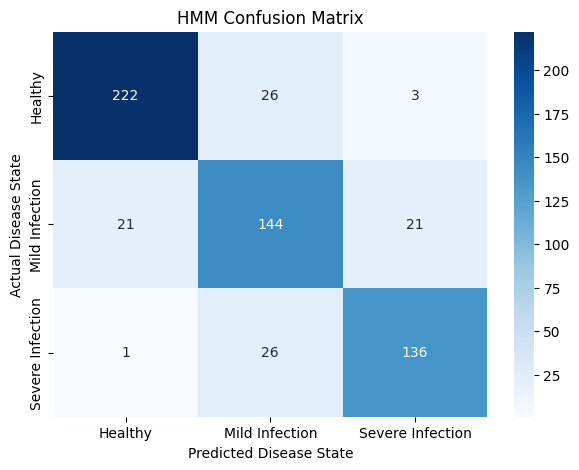

In [ ]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=states,
    yticklabels=states
)

plt.xlabel("Predicted Disease State")
plt.ylabel("Actual Disease State")
plt.title("HMM Confusion Matrix")

plt.show()

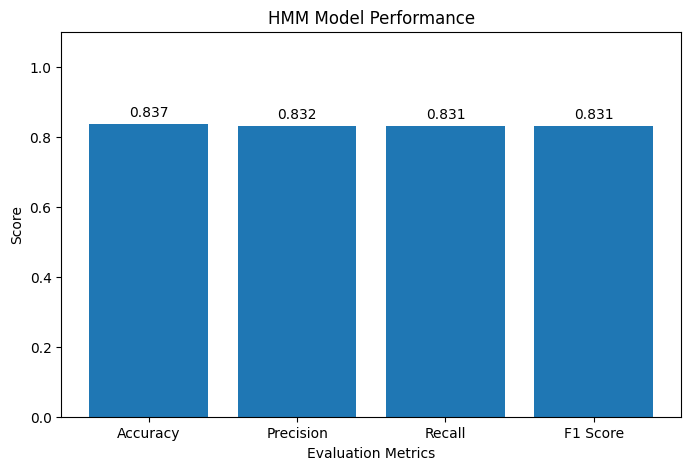

In [ ]:
metrics = {
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1 Score": f1
}

plt.figure(figsize=(8, 5))

plt.bar(
    metrics.keys(),
    metrics.values()
)

plt.ylim(0, 1.1)
plt.ylabel("Score")
plt.xlabel("Evaluation Metrics")
plt.title("HMM Model Performance")

for i, value in enumerate(metrics.values()):

    plt.text(
        i, value + 0.02,
        f"{value:.3f}",
        ha="center"
    )

plt.show()

In [ ]:
def evaluate_experiment(n, length):

    obs_data = []
    state_data = []

    for i in range(n):

        hidden, observed = generate_patient(
            true_pi, true_A, true_B, length
        )

        state_data.append(hidden)
        obs_data.append(observed)

    split = int(0.8 * n)

    train_obs = obs_data[:split]
    test_obs = obs_data[split:]
    test_states = state_data[split:]

    # Fresh initialization
    init_pi = np.array([0.65, 0.25, 0.10])

    init_A = np.array([
        [0.75, 0.20, 0.05],
        [0.12, 0.68, 0.20],
        [0.05, 0.20, 0.75]
    ])

    init_B = np.array([
        [0.80, 0.15, 0.03, 0.02],
        [0.15, 0.50, 0.28, 0.07],
        [0.03, 0.12, 0.45, 0.40]
    ])

    p, a, b = baum_welch(
        train_obs,
        init_pi,
        init_A,
        init_B,
        iterations=50
    )

    actual = []
    predicted = []

    for i in range(len(test_obs)):

        actual.extend(test_states[i])

        predicted.extend(
            viterbi(test_obs[i], p, a, b)
        )

    return accuracy_score(actual, predicted)


dataset_sizes = [50, 100, 150, 200, 300]

size_results = []

for size in dataset_sizes:

    score = evaluate_experiment(size, 10)

    size_results.append(score)

    print(
        "Patients:", size,
        "Accuracy:", round(score, 4)
    )

Patients: 50 Accuracy: 0.61
Patients: 100 Accuracy: 0.8
Patients: 150 Accuracy: 0.7533
Patients: 200 Accuracy: 0.79
Patients: 300 Accuracy: 0.8267


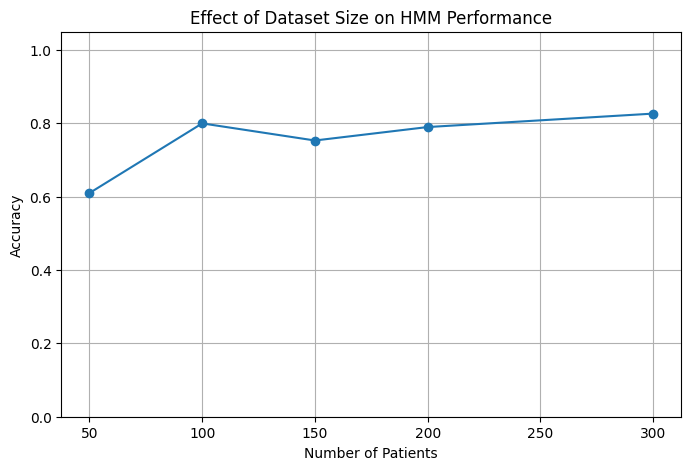

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    dataset_sizes,
    size_results,
    marker="o"
)

plt.xlabel("Number of Patients")
plt.ylabel("Accuracy")
plt.title("Effect of Dataset Size on HMM Performance")

plt.ylim(0, 1.05)
plt.grid(True)

plt.show()

In [ ]:
sequence_lengths = [5, 10, 15, 20]

length_results = []

for length in sequence_lengths:

    score = evaluate_experiment(300, length)

    length_results.append(score)

    print(
        "Sequence Length:", length,
        "Accuracy:", round(score, 4)
    )

Sequence Length: 5 Accuracy: 0.7867
Sequence Length: 10 Accuracy: 0.7717
Sequence Length: 15 Accuracy: 0.8144
Sequence Length: 20 Accuracy: 0.8025


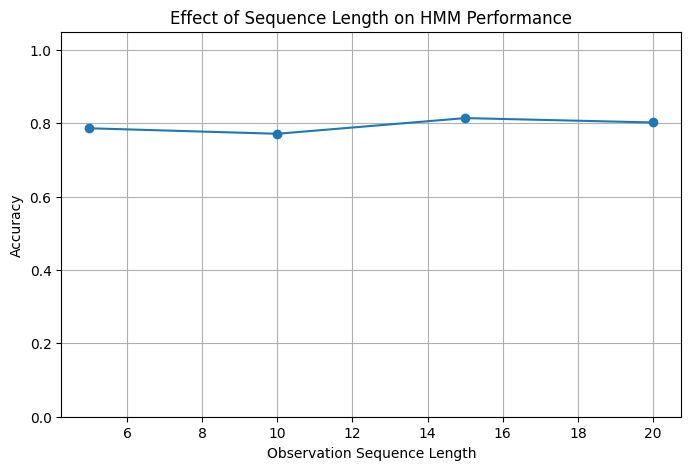

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    sequence_lengths,
    length_results,
    marker="o"
)

plt.xlabel("Observation Sequence Length")
plt.ylabel("Accuracy")
plt.title("Effect of Sequence Length on HMM Performance")

plt.ylim(0, 1.05)
plt.grid(True)

plt.show()

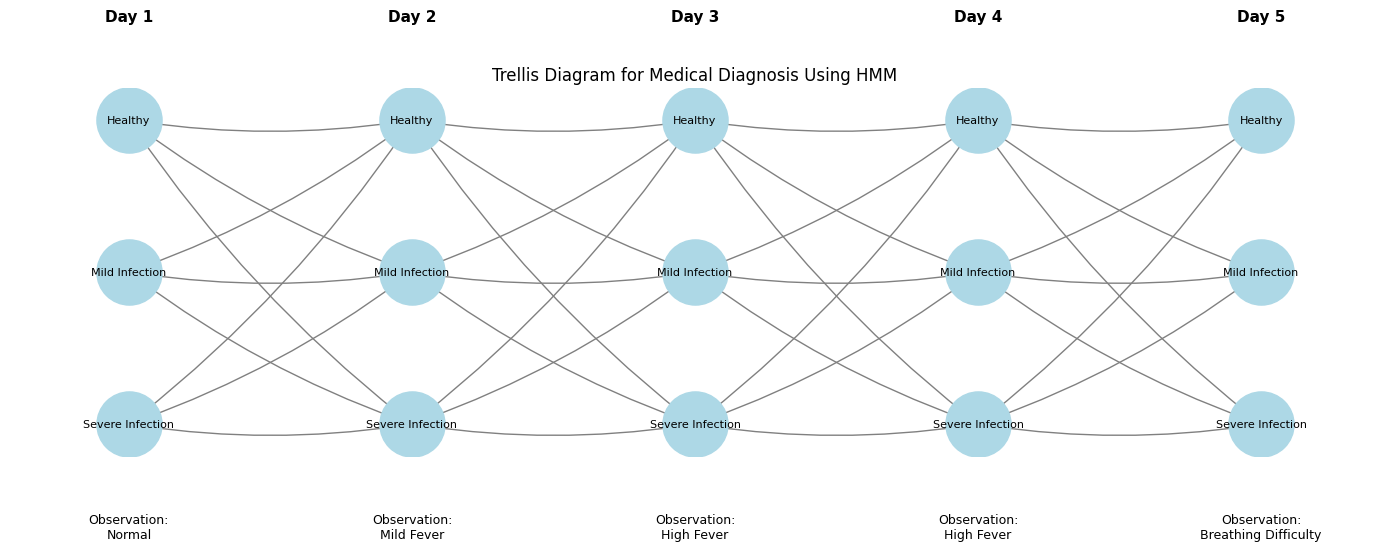

In [ ]:

import matplotlib.pyplot as plt
import networkx as nx

# Hidden states
states = ["Healthy", "Mild Infection", "Severe Infection"]

# Sample observations for 5 days
observations = [
    "Normal",
    "Mild Fever",
    "High Fever",
    "High Fever",
    "Breathing Difficulty"
]

# Transition probabilities
A = [
    [0.80, 0.18, 0.02],
    [0.10, 0.70, 0.20],
    [0.05, 0.15, 0.80]
]

# Create graph
G = nx.DiGraph()

# Add nodes for each day and state
for day in range(len(observations)):
    for state in range(len(states)):
        G.add_node((day, state))

# Add edges between consecutive days
for day in range(len(observations) - 1):
    for i in range(len(states)):
        for j in range(len(states)):
            G.add_edge(
                (day, i),
                (day + 1, j),
                weight=A[i][j]
            )

# Position nodes
pos = {}
for day in range(len(observations)):
    for state in range(len(states)):
        pos[(day, state)] = (day, 2 - state)

# Draw trellis diagram
plt.figure(figsize=(14, 6))

nx.draw_networkx_nodes(
    G, pos,
    node_size=2200,
    node_color="lightblue"
)

nx.draw_networkx_labels(
    G, pos,
    labels={(day, state): states[state]
            for day in range(len(observations))
            for state in range(len(states))},
    font_size=8
)

nx.draw_networkx_edges(
    G, pos,
    arrows=True,
    arrowstyle="->",
    arrowsize=12,
    edge_color="gray",
    width=1,
    connectionstyle="arc3,rad=0.08"
)

# Add day labels and observations
for day, observation in enumerate(observations):
    plt.text(day, 2.65, f"Day {day+1}",
             ha="center", fontsize=11, fontweight="bold")
    plt.text(day, -0.75, f"Observation:\n{observation}",
             ha="center", fontsize=9)

plt.title("Trellis Diagram for Medical Diagnosis Using HMM")
plt.axis("off")
plt.tight_layout()
plt.show()
